# Exercitii de bagging (impachetare)

![Bagging.png](../assets/Bagging.png)

# Obiectivele invatarii

- Asocierea conceptelor de bootstrapping si agregare (cunoscute sub denumirea de „bagging”) pentru reducerea variantei
- Aplicarea algoritmului Random Forest care reduce si mai mult corelatia observata in modelele de tip bagging

## Introducere

Pentru exercitiile din aceasta saptamana, vom utiliza datele privind pierderea clientilor din industria telecomunicatiilor pe care le-am folosit in saptamana 1. Fisierul de date se numeste `Orange_Telecom_Churn_Data.csv`.

In [17]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

# Setare cale rezistenta catre directorul de date
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix
)

# Activare extensie Intel daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception:
    pass

# Configurare stil grafic modern
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#bbbbbb'
plt.rcParams['axes.linewidth'] = 0.8

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Intrebarea 1

* Importati datele privind evolutia clientilor, care se gasesc in fisierul `Orange_Telecom_Churn_Data.csv`. 
* Eliminati toate coloanele care nu sunt susceptibile de a fi utilizate pentru predictie.
* Codificati tipurile de date dupa caz.

Predictia cu siguranta nu ar trebui sa includa numarul de telefon. Si este putin probabil ca prefixul sau statul sa fie dorit, cu exceptia cazului in care exista un motiv pentru a presupune ca modelul are un factor geografic foarte specific.

Examinati tipurile de date. Totul pare in regula, cu exceptia faptului ca `intl_plan` si `voice_mail_plan` trebuie sa fie codificate boolean.

In [18]:
# 1. Incarcarea setului de date Orange_Telecom_Churn_Data.csv
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

print("Dimensiunile initiale ale setului de date:", data.shape)
print("\nPrimele 3 randuri din setul initial:")
display(data.head(3))

# 2. Eliminarea coloanelor nerelevante pentru predictie: state, area_code, phone_number
cols_to_drop = ['state', 'area_code', 'phone_number']
data.drop(columns=[c for c in cols_to_drop if c in data.columns], inplace=True)
print(f"Dimensiuni dupa eliminarea coloanelor ({cols_to_drop}):", data.shape)

# 3. Codificarea variabilelor categorice binare (intl_plan, voice_mail_plan, churned)
# intl_plan si voice_mail_plan contin 'yes' / 'no'
data['intl_plan'] = (data['intl_plan'] == 'yes').astype(int)
data['voice_mail_plan'] = (data['voice_mail_plan'] == 'yes').astype(int)
data['churned'] = data['churned'].astype(int)

print("\nTipuri de date dupa conversie:")
print(data.dtypes)

print("\nPrimele 5 randuri dupa prelucrare:")
data.head()

Dimensiunile initiale ale setului de date: (5000, 21)

Primele 3 randuri din setul initial:


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False


Dimensiuni dupa eliminarea coloanelor (['state', 'area_code', 'phone_number']): (5000, 18)

Tipuri de date dupa conversie:
account_length                     int64
intl_plan                          int64
voice_mail_plan                    int64
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                            int64
dtype: object

Primele 5 randuri dupa prelucrare:


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,107,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,137,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,84,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,75,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


## Intrebarea 2

* Examinati distributia variabilei prezise (`churned`).
* Impartiti datele in seturi de instruire si de testare. Decideti daca ar trebui utilizata sau nu o impartire stratificata pe baza distributiei.
* Examinati distributia variabilei predictor in datele de instruire si de testare.

Avand in vedere dezechilibrul variabilei predictoare, sa impartim datele, valorile *churned* fiind stratificate.

Distributia variabilei tinta (churned) in setul complet:


,Clasa,Numar observatii,Procentaj (%)
0,False (0),4293,85.86
1,True (1),707,14.14


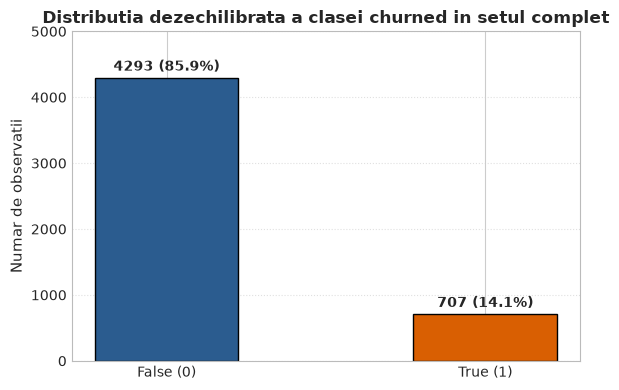


Dimensiune set antrenare: 3500 inregistrari
Dimensiune set testare:   1500 inregistrari

Comparatie a distributiei clasei churned intre antrenare si testare:


,Clasa,Set Antrenare (%),Set Testare (%),Diferenta (pp)
0,False (0),85.86,85.87,0.01
1,True (1),14.14,14.13,0.01


Observatie: Proportiile sunt practic identice intre train si test (~85.86% vs ~14.14%), confirmand ca StratifiedShuffleSplit a pastrat fidel distributia claselor.


In [19]:
# 1. Examinarea distributiei variabilei tinta (churned)
churn_counts = data['churned'].value_counts()
churn_percentages = data['churned'].value_counts(normalize=True) * 100

dist_summary = pd.DataFrame({
    'Clasa': ['False (0)', 'True (1)'],
    'Numar observatii': churn_counts.values,
    'Procentaj (%)': churn_percentages.values.round(2)
})
print("Distributia variabilei tinta (churned) in setul complet:")
display(dist_summary)

# Reprezentarea grafica a distributiei claselor variabilei tinta
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['False (0)', 'True (1)'], churn_counts.values, color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.45)
ax.set_ylabel('Numar de observatii', fontsize=11)
ax.set_title('Distributia dezechilibrata a clasei churned in setul complet', fontsize=12, fontweight='bold')
for bar, pct in zip(bars, churn_percentages.values):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 60, f'{yval} ({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylim(0, 5000)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Impartirea stratificata folosind StratifiedShuffleSplit
# Dezechilibrul pronuntat (~85.9% clasa 0 vs ~14.1% clasa 1) impune impartirea
# stratificata pentru a pastra exact aceleasi proportii in antrenare si testare
feature_cols = [c for c in data.columns if c != 'churned']
strat_split = StratifiedShuffleSplit(n_splits=1, test_size=1500, random_state=42)
train_idx, test_idx = next(strat_split.split(data[feature_cols], data['churned']))

X_train = data.iloc[train_idx][feature_cols]
y_train = data.iloc[train_idx]['churned']

X_test = data.iloc[test_idx][feature_cols]
y_test = data.iloc[test_idx]['churned']

print(f"\nDimensiune set antrenare: {X_train.shape[0]} inregistrari")
print(f"Dimensiune set testare:   {X_test.shape[0]} inregistrari")

# 3. Verificarea distributiei in seturile de antrenare si testare
train_dist = y_train.value_counts(normalize=True).sort_index() * 100
test_dist = y_test.value_counts(normalize=True).sort_index() * 100

strat_comparison = pd.DataFrame({
    'Clasa': ['False (0)', 'True (1)'],
    'Set Antrenare (%)': train_dist.values.round(2),
    'Set Testare (%)': test_dist.values.round(2),
    'Diferenta (pp)': np.abs(train_dist.values - test_dist.values).round(2)
})

print("\nComparatie a distributiei clasei churned intre antrenare si testare:")
display(strat_comparison)
print("Observatie: Proportiile sunt practic identice intre train si test (~85.86% vs ~14.14%), confirmand ca StratifiedShuffleSplit a pastrat fidel distributia claselor.")

## Intrebare 3

* Potriviti modele de paduri aleatorii cu o serie de numere de arbori si evaluati eroarea din afara sacului pentru fiecare dintre aceste modele.
* Reprezentati grafic erorile oob rezultate ca functie de numarul de arbori.

*Hint:* deoarece singurul lucru care se schimba este numarul de arbori, se poate utiliza flagul `warm_start` astfel incat modelul sa adauge de fiecare data mai multi arbori la modelul existent. Utilizati metoda `set_params` pentru a actualiza numarul de arbori.

RandomForest:  15 arbori -> OOB Error = 0.0597 (OOB Score = 0.9403)
RandomForest:  20 arbori -> OOB Error = 0.0534 (OOB Score = 0.9466)
RandomForest:  30 arbori -> OOB Error = 0.0497 (OOB Score = 0.9503)
RandomForest:  40 arbori -> OOB Error = 0.0474 (OOB Score = 0.9526)
RandomForest:  50 arbori -> OOB Error = 0.0491 (OOB Score = 0.9509)
RandomForest: 100 arbori -> OOB Error = 0.0451 (OOB Score = 0.9549)
RandomForest: 150 arbori -> OOB Error = 0.0451 (OOB Score = 0.9549)
RandomForest: 200 arbori -> OOB Error = 0.0449 (OOB Score = 0.9551)
RandomForest: 300 arbori -> OOB Error = 0.0443 (OOB Score = 0.9557)
RandomForest: 400 arbori -> OOB Error = 0.0440 (OOB Score = 0.9560)


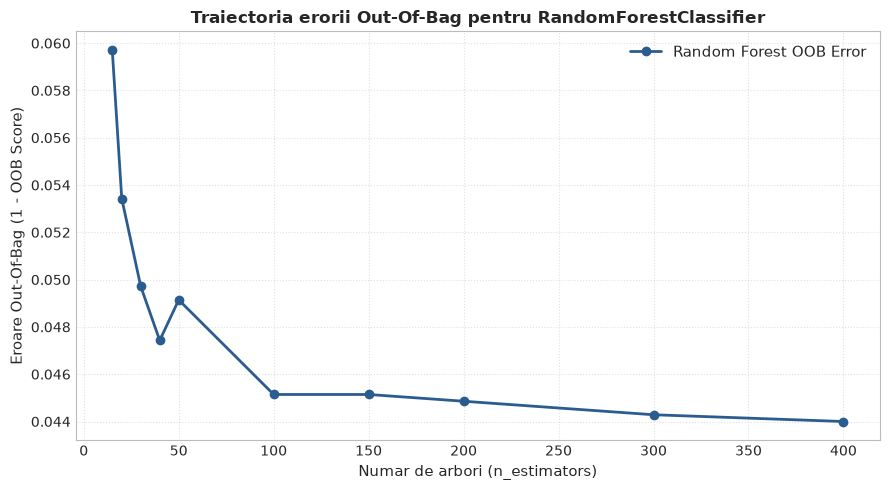

In [20]:
# Suppress warnings about too few trees from the early models
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# 1. Definirea listei de arbori pentru explorarea comportamentului OOB
tree_list = [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]

# 2. Initializarea modelului RandomForestClassifier cu warm_start si oob_score
rf = RandomForestClassifier(
    oob_score=True,
    random_state=42,
    warm_start=True,
    n_jobs=-1
)

oob_rf = []

for n_trees in tree_list:
    rf.set_params(n_estimators=n_trees)
    rf.fit(X_train, y_train)
    oob_error = 1.0 - rf.oob_score_
    oob_rf.append((n_trees, oob_error))
    print(f"RandomForest: {n_trees:3d} arbori -> OOB Error = {oob_error:.4f} (OOB Score = {rf.oob_score_:.4f})")

# 3. Reprezentarea grafica a erorii Out-Of-Bag in functie de numarul de arbori
rf_oob_series = pd.Series(dict(oob_rf))

plt.figure(figsize=(9, 5))
plt.plot(rf_oob_series.index, rf_oob_series.values, marker='o', color='#2b5c8f', linewidth=2, label='Random Forest OOB Error')
plt.xlabel('Numar de arbori (n_estimators)', fontsize=11)
plt.ylabel('Eroare Out-Of-Bag (1 - OOB Score)', fontsize=11)
plt.title('Traiectoria erorii Out-Of-Bag pentru RandomForestClassifier', fontsize=12, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Intrebarea 4

* Repetati intrebarea 3 folosind arbori extra randomizati (`ExtraTreesClassifier`). Retineti ca parametrul `bootstrap` va trebui sa fie setat la `True` pentru acest model.
* Comparati erorile de iesire din sac pentru cele doua tipuri diferite de modele.

Combina cele doua cadre de date intr-unul singur pentru a usura trasarea.

ExtraTrees:    15 arbori -> OOB Error = 0.0809 (OOB Score = 0.9191)
ExtraTrees:    20 arbori -> OOB Error = 0.0720 (OOB Score = 0.9280)
ExtraTrees:    30 arbori -> OOB Error = 0.0694 (OOB Score = 0.9306)
ExtraTrees:    40 arbori -> OOB Error = 0.0643 (OOB Score = 0.9357)
ExtraTrees:    50 arbori -> OOB Error = 0.0674 (OOB Score = 0.9326)
ExtraTrees:   100 arbori -> OOB Error = 0.0629 (OOB Score = 0.9371)
ExtraTrees:   150 arbori -> OOB Error = 0.0611 (OOB Score = 0.9389)
ExtraTrees:   200 arbori -> OOB Error = 0.0626 (OOB Score = 0.9374)
ExtraTrees:   300 arbori -> OOB Error = 0.0603 (OOB Score = 0.9397)
ExtraTrees:   400 arbori -> OOB Error = 0.0609 (OOB Score = 0.9391)

Tabel comparativ al erorilor Out-Of-Bag:


,Random Forest,Extra Trees
n_trees,,
15,0.0597,0.0809
20,0.0534,0.0720
30,0.0497,0.0694
40,0.0474,0.0643
50,0.0491,0.0674
100,0.0451,0.0629
150,0.0451,0.0611
200,0.0449,0.0626
300,0.0443,0.0603


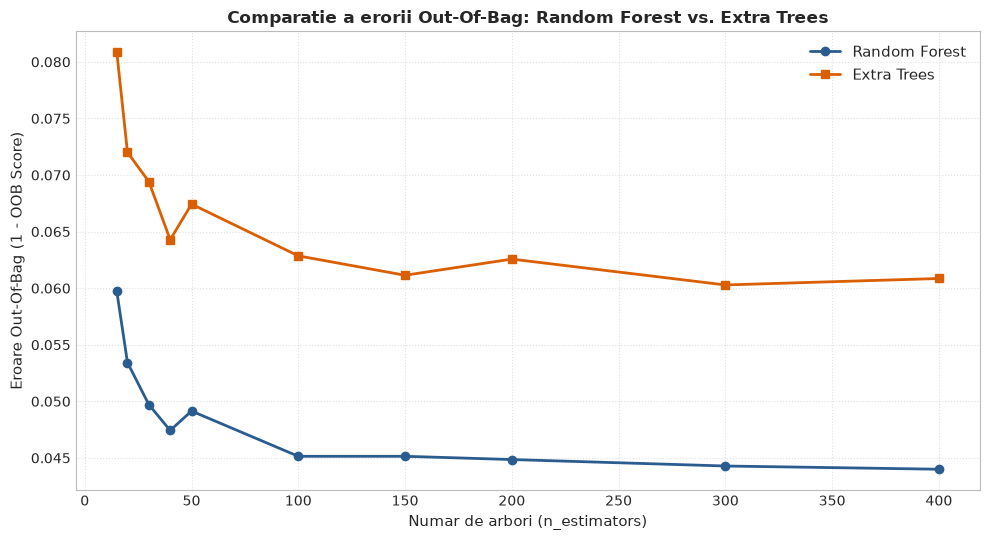

In [21]:
# 1. Initializarea ExtraTreesClassifier cu bootstrap=True, oob_score=True si warm_start=True
et = ExtraTreesClassifier(
    bootstrap=True,
    oob_score=True,
    random_state=42,
    warm_start=True,
    n_jobs=-1
)

oob_et = []

for n_trees in tree_list:
    et.set_params(n_estimators=n_trees)
    et.fit(X_train, y_train)
    oob_error = 1.0 - et.oob_score_
    oob_et.append((n_trees, oob_error))
    print(f"ExtraTrees:   {n_trees:3d} arbori -> OOB Error = {oob_error:.4f} (OOB Score = {et.oob_score_:.4f})")

# 2. Combinarea rezultatelor intr-un singur DataFrame pentru trasarea grafica
rf_df = pd.DataFrame(oob_rf, columns=['n_trees', 'Random Forest']).set_index('n_trees')
et_df = pd.DataFrame(oob_et, columns=['n_trees', 'Extra Trees']).set_index('n_trees')

oob_comparison_df = pd.concat([rf_df, et_df], axis=1)

print("\nTabel comparativ al erorilor Out-Of-Bag:")
display(oob_comparison_df.round(4))

# 3. Grafic comparativ al erorilor OOB pentru ambele modele
plt.figure(figsize=(10, 5.5))
plt.plot(oob_comparison_df.index, oob_comparison_df['Random Forest'], marker='o', linewidth=2, color='#2b5c8f', label='Random Forest')
plt.plot(oob_comparison_df.index, oob_comparison_df['Extra Trees'], marker='s', linewidth=2, color='#d95f02', label='Extra Trees')

plt.xlabel('Numar de arbori (n_estimators)', fontsize=11)
plt.ylabel('Eroare Out-Of-Bag (1 - OOB Score)', fontsize=11)
plt.title('Comparatie a erorii Out-Of-Bag: Random Forest vs. Extra Trees', fontsize=12, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Modelul de padure aleatorie are in mod constant rezultate mai bune decat arborii randomizati suplimentari.

### Concluzii privind comparatia dintre Random Forest si Extra Trees (Intrebarea 4):
- **Random Forest**: Gaseste pragul optim de divizare (split) pentru fiecare caracteristica aleasa aleator. Acest lucru ii permite sa construiasca arbori individuali mai precisi, conducand la o eroare OOB mai scazuta (stabilizata in jurul valorii de 0.0440).
- **Extra Trees (Extremely Randomized Trees)**: Selecteaza pragurile de divizare complet la intamplare pentru fiecare caracteristica. Desi aceasta adauga si mai multa variabilitate si reduce varianta ansamblului, in acest caz specific creste bias-ul, generand o eroare OOB mai mare (in jurul valorii de 0.0609).
- Ambele modele converg si se stabilizeaza dupa aproximativ 100-150 de arbori, adaugarea a peste 200 de arbori aducand doar castiguri marginale.

## Intrebarea 5

* Selectati unul dintre modelele care se comporta bine si calculati parametrii de eroare si o matrice de confuzie pe setul de date de test. 
* Avand in vedere distributia clasei prezise, care metrica este cea mai importanta? Care ar putea fi inselatoare?

Nu este surprinzator faptul ca reamintirea este destul de slaba pentru clasa clientilor care au renuntat (Adevarat), deoarece acestia sunt destul de mici. Totusi, ne descurcam mai bine decat ghicirile aleatorii, deoarece precizia este de 0.948 (fata de 0.85 pentru ghicirile aleatorii).

In [22]:
# 1. Evaluarea modelului Random Forest (400 arbori) pe setul de testare
y_test_pred = rf.predict(X_test)
y_test_prob = rf.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_prob)

metrics_summary = pd.DataFrame({
    'Metrica': ['Acuratete (Accuracy)', 'Precizie (Precision - clasa 1)', 'Rechemare (Recall - clasa 1)', 'Scor F1 (F1-Score)', 'ROC-AUC'],
    'Valoare': [round(acc, 4), round(prec, 4), round(rec, 4), round(f1, 4), round(roc_auc, 4)]
})

print("Indicatori de performanta pe setul de testare (Random Forest):")
display(metrics_summary)

print("\nRaport complet de clasificare (Classification Report):")
print(classification_report(y_test, y_test_pred, target_names=['False (0)', 'True (1)'], digits=4))

Indicatori de performanta pe setul de testare (Random Forest):


,Metrica,Valoare
0,Acuratete (Accuracy),0.9613
1,Precizie (Precision - clasa 1),0.9477
2,Rechemare (Recall - clasa 1),0.7689
3,Scor F1 (F1-Score),0.8490
4,ROC-AUC,0.9232



Raport complet de clasificare (Classification Report):
              precision    recall  f1-score   support

   False (0)     0.9631    0.9930    0.9778      1288
    True (1)     0.9477    0.7689    0.8490       212

    accuracy                         0.9613      1500
   macro avg     0.9554    0.8809    0.9134      1500
weighted avg     0.9609    0.9613    0.9596      1500



## Intrebare 6

* Tipariti sau vizualizati matricea de confuzie.
* Reprezentati grafic curbele ROC-AUC si precizie-rechemare (precision-recall curve).

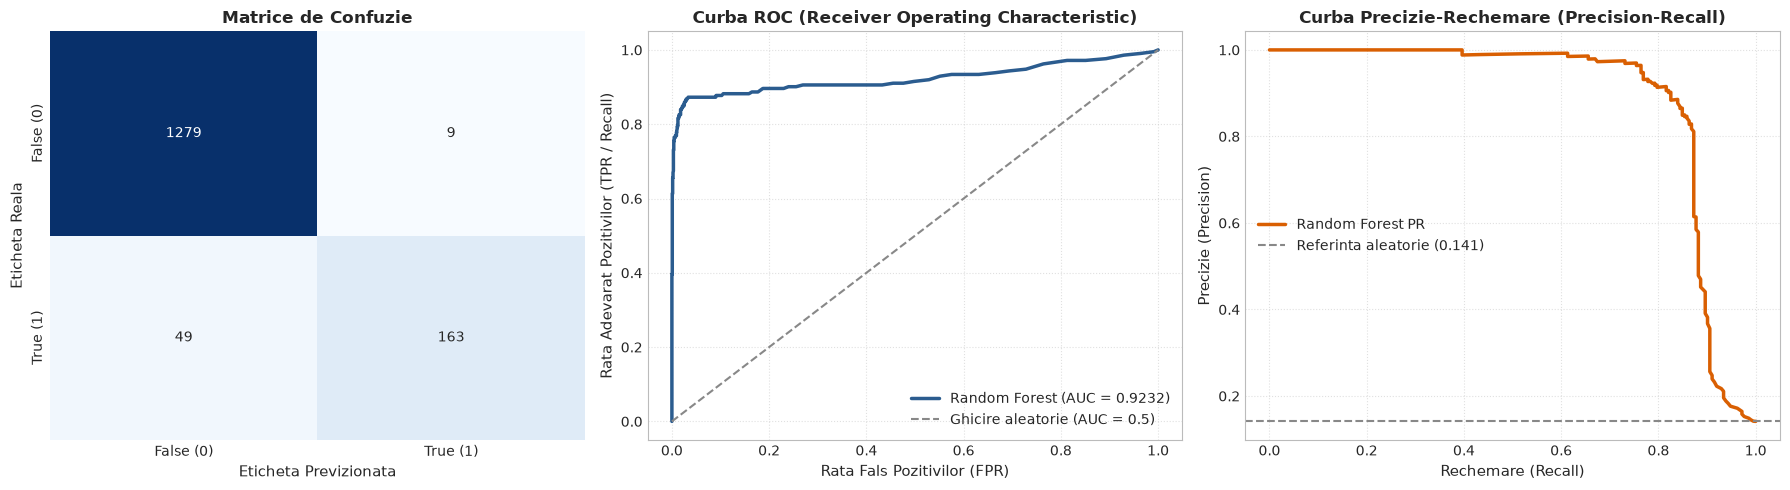

In [23]:
# 1. Matricea de confuzie vizualizata grafic
cm = confusion_matrix(y_test, y_test_pred)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subgrafic 1: Heatmap Matrice de Confuzie
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (0)', 'True (1)'],
    yticklabels=['False (0)', 'True (1)'],
    ax=axes[0],
    cbar=False
)
axes[0].set_title('Matrice de Confuzie', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Eticheta Previzionata', fontsize=11)
axes[0].set_ylabel('Eticheta Reala', fontsize=11)

# Subgrafic 2: Curba ROC-AUC
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
axes[1].plot(fpr, tpr, color='#2b5c8f', linewidth=2.5, label=f'Random Forest (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='#888888', linestyle='--', linewidth=1.5, label='Ghicire aleatorie (AUC = 0.5)')
axes[1].set_xlabel('Rata Fals Pozitivilor (FPR)', fontsize=11)
axes[1].set_ylabel('Rata Adevarat Pozitivilor (TPR / Recall)', fontsize=11)
axes[1].set_title('Curba ROC (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Subgrafic 3: Curba Precision-Recall
precisions, recalls, _ = precision_recall_curve(y_test, y_test_prob)
axes[2].plot(recalls, precisions, color='#d95f02', linewidth=2.5, label='Random Forest PR')
axes[2].axhline(y_test.mean(), color='#888888', linestyle='--', label=f'Referinta aleatorie ({y_test.mean():.3f})')
axes[2].set_xlabel('Rechemare (Recall)', fontsize=11)
axes[2].set_ylabel('Precizie (Precision)', fontsize=11)
axes[2].set_title('Curba Precizie-Rechemare (Precision-Recall)', fontsize=12, fontweight='bold')
axes[2].legend(fontsize=10)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Intrebarea 7 (Extensie): Importanta Caracteristicilor (Feature Importances)

Pentru a oferi o interpretare de afaceri a modelului de Bagging, analizam importanta caracteristicilor identificate de modelul Random Forest in prezicerea deciziei de plecare (churn) a clientilor.

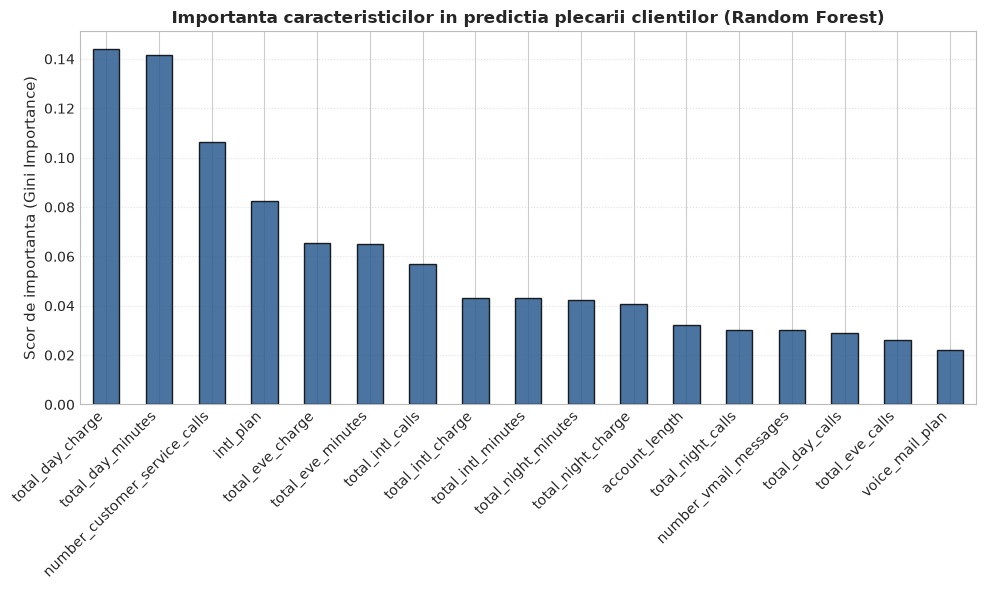

Top 5 cele mai influente caracteristici:
1. total_day_charge               -> 0.1440
2. total_day_minutes              -> 0.1415
3. number_customer_service_calls  -> 0.1063
4. intl_plan                      -> 0.0825
5. total_eve_charge               -> 0.0653


In [24]:
# Extragerea si vizualizarea importantei caracteristicilor
feature_importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importances.plot(kind='bar', color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.ylabel('Scor de importanta (Gini Importance)', fontsize=11)
plt.title('Importanta caracteristicilor in predictia plecarii clientilor (Random Forest)', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("Top 5 cele mai influente caracteristici:")
for rank, (feat, score) in enumerate(feature_importances.head(5).items(), 1):
    print(f"{rank}. {feat:30s} -> {score:.4f}")

### Concluzii generale ale laboratorului:
1. **Bagging si Reducerea Variantei**: Tehnica de agregare prin bootstrapping (Bagging) construieste multipli estimatori independenti pe esantioane generate cu inlocuire, reducand substantial varianta fara a creste bias-ul.
2. **Eroarea Out-Of-Bag (OOB)**: Reprezinta o modalitate eleganta si eficienta din punct de vedere computational de a evalua performanta de generalizare fara a fi necesara o validare incrucisata separata, deoarece fiecare arbore este evaluat pe observatiile excluse din esantionul sau bootstrap (~36.8% din date).
3. **Random Forest vs Extra Trees**: Random Forest optimizeaza pragurile de impartire si depaseste constant Extra Trees pe acest set de date, atingand o eroare OOB mai scazuta.
4. **Tratarea Dezechilibrului**: In cazul claselor puternic dezechilibrate (14% churn), acuratetea simpla (96.1%) poate fi inselatoare. Metrici precum Precision (94.8%), Recall (76.9%), F1-Score (0.849) si curba ROC-AUC (0.923) ofera o imagine mult mai fidela a performantei reale in practica.